# 06 · Modelo de pronóstico (Capa 1)
LightGBM global entrenado a nivel diario sobre `log(amount_total)`, con horizonte directo de 14 días. La meta se mide en **tienda × categoría × semana** con WAPE (sesgo siempre a la vista), contra los baselines del notebook 05.

**Protocolo (definido antes de ver resultados)**
- **Desarrollo** (elegir variantes e hiperparámetros): `semana_santa_2023`, `may_jun_2023`, `sep_2023`.
- **Confirmación** (solo verifica la elección): `oct_2023`, `feb_2024`.
- **Evento y post-evento** (Buen Fin, Navidad, enero–febrero): se reportan, nunca se usan para seleccionar.
- **Regla de decisión:** un cambio se adopta solo si mejora el WAPE medio de desarrollo ≥ 0.2 puntos (≈ 1/8 del margen disponible sobre el baseline). Con 2 a 4 semanas por fold, diferencias menores no son distinguibles del azar.

Antes de fijar este protocolo se hizo una exploración rápida del modelo base con todos los folds (sin ajustar nada); por eso las ablaciones usan una regla explícita y no «lo que salga mejor».

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import json, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from sklearn.metrics import r2_score
from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.features.engineering import FeatureConfig, build_features
from src.features.targets import unit_price_by_series, derive_units
from src.models.backtest import FOLDS, evaluate, evaluate_by, aggregate
from src.models.evaluate import wape, mape, bias
from src.models.significance import compare
from src.models import train as T
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 150, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format)
t, s, c = load_transactions(), load_stores(), load_calendar(); p = build_panel(t, s, c)
cfg = FeatureConfig(horizon=14); F = build_features(p, cfg); cols = cfg.feature_columns(); P0 = dict(T.DEFAULT_PARAMS)
print(len(cols), 'features |', F.eligible.sum(), 'filas elegibles | desarrollo:', T.DEV_FOLDS, '| confirmación:', T.CONFIRM_FOLDS)

30 features | 190998 filas elegibles | desarrollo: ['semana_santa_2023', 'may_jun_2023', 'sep_2023'] | confirmación: ['oct_2023', 'feb_2024']


## 1. Backtest walk-forward con configuración de referencia

In [2]:
preds0 = T.run_backtest(F, cfg, P0, cols); M0 = T.fold_metrics(preds0)
W = M0.pivot_table(index=['tipo', 'fold'], columns='modelo', values='wape').mul(100)[['modelo', 'sma4', 'snaive', 'ma28']]
B = M0.pivot_table(index=['tipo', 'fold'], columns='modelo', values='bias').mul(100)[['modelo', 'sma4']]
print('WAPE % y sesgo % (tienda × categoría × semana, horizonte 14):'); W.join(B, rsuffix=' (sesgo)').round(1)

WAPE % y sesgo % (tienda × categoría × semana, horizonte 14):


modelo                         modelo  sma4  snaive  ma28  modelo (sesgo)  sma4 (sesgo)
tipo        fold                                                                       
evento      buen_fin_2023       34.50 31.50   40.20 33.40          -34.20        -28.90
            navidad_2023        28.50 29.20   36.80 25.50           -8.60         -3.60
post_evento post_navidad_2024   57.90 62.90   37.80 71.70           57.40         61.70
regular     feb_2024             7.10  7.80    9.00  7.80           -1.40         -3.90
            may_jun_2023         7.00  8.10    8.90  8.20           -1.40         -5.40
            oct_2023             7.80  8.00    9.30  8.10            3.90          4.30
            semana_santa_2023    7.60  8.70    9.70  8.70           -3.60         -2.40
            sep_2023             8.20  8.10    9.30  8.10            3.00          2.80

### 1.1 ¿La mejora es estadísticamente significativa?
Las series comparten choques semanales, así que no son independientes: se agrega el error por semana y se remuestrea por semanas (bootstrap por bloques); además prueba de Wilcoxon sobre las diferencias semanales.

In [3]:
rows = {}
for lab, sel in [('regulares (5 folds)', preds0.kind == 'regular'), ('desarrollo', preds0.fold.isin(T.DEV_FOLDS)), ('confirmación', preds0.fold.isin(T.CONFIRM_FOLDS)),
                 ('eventos', preds0.kind == 'evento'), ('post_evento', preds0.kind == 'post_evento')]:
    rows[lab] = compare(preds0[sel], 'pred', 'base_sma4')
S = pd.DataFrame(rows).T; S.columns = ['WAPE modelo', 'WAPE sma4', 'Δ pts', 'IC95 inf', 'IC95 sup', 'p (bootstrap)', 'semanas', 'semanas modelo mejor', 'p Wilcoxon']; S

,WAPE modelo,WAPE sma4,Δ pts,IC95 inf,IC95 sup,p (bootstrap),semanas,semanas modelo mejor,p Wilcoxon
regulares (5 folds),7.59,8.19,-0.60,-1.11,-0.15,0.01,18.00,11.00,0.04
desarrollo,7.60,8.30,-0.70,-1.37,-0.13,0.02,12.00,7.00,0.13
confirmación,7.55,7.95,-0.40,-0.98,0.24,0.21,6.00,4.00,0.31
eventos,31.46,30.35,1.11,-3.02,3.25,0.51,8.00,1.00,0.20
post_evento,57.87,62.87,-5.00,-12.32,2.12,0.17,5.00,3.00,NaN


**Lectura.**
- En los 5 folds regulares el modelo obtiene WAPE 7.6 % contra 8.2 % de `sma4` (−0.6 pts, ≈ 7 % relativo). Gana en 4 de 5 folds; en `sep_2023` queda empatado (8.2 vs 8.1).
- La diferencia es modesta pero estable: IC95 por bootstrap de semanas [−1.1, −0.15] y Wilcoxon p = 0.04 (el modelo gana 11 de 18 semanas). Con tan pocas semanas la evidencia es moderada, no contundente: en desarrollo (12 semanas) Wilcoxon da p = 0.13 y la confirmación por sí sola (6 semanas) tiene un IC que cruza el cero ([−0.98, +0.24]).
- Contexto: el piso de ruido en serie × semana es ≈ 6.5 %, es decir, `sma4` está a 1.7 pts del piso y el modelo recorta ≈ 0.6 pts (≈ un tercio del margen). El piso es en muestra, así que el margen real es algo menor.
- **Eventos y post-evento: el modelo no es mejor que el baseline** (Buen Fin 34.5 vs 31.5; sesgo −34 %; post-Navidad 57.9 vs 62.9 con sesgo +57 %, y el mejor baseline es `snaive` con 37.8). Cada evento ocurre una sola vez en los datos, de modo que ningún método puede aprender su magnitud; se reportan como prueba de estrés y no se usan para decidir nada.

## 2. Ablaciones (variantes de features y objetivo)
Cada variante se evalúa con la misma regla: se adopta solo si mejora el WAPE medio de desarrollo ≥ 0.2 puntos.

In [4]:
STORE_ALL = ('store_format', 'socioeconomic_level', 'region', 'size_sqm', 'num_checkouts', 'opening_year', 'has_pharmacy', 'has_fuel_station')
drop = lambda cs, ex: [x for x in cs if x not in ex]
CAL_DIST = ['days_to_payday', 'days_since_payday', 'days_to_holiday', 'days_since_holiday', 'days_to_christmas', 'buen_fin_day', 'days_to_buen_fin', 'days_since_buen_fin']
EVT = ['is_buen_fin', 'is_navidad_season', 'buen_fin_day', 'days_to_buen_fin', 'days_since_buen_fin', 'days_to_christmas']
cfgs = {'base': cfg, 'seasonal': FeatureConfig(14, use_seasonal_position=True), 'store': FeatureConfig(14, store_features=STORE_ALL), 'event': FeatureConfig(14, event_aware=True)}
FF = {k: (F if k == 'base' else build_features(p, v)) for k, v in cfgs.items()}
V = {'base (30 features, objetivo L2 en log)': ('base', cols, {}),
     '+ month y week_of_year': ('seasonal', cfgs['seasonal'].feature_columns(), {}),
     '+ atributos de tienda (región, m², cajas, farmacia, gasolinera, año)': ('store', cfgs['store'].feature_columns(), {}),
     '+ rezagos limpios que excluyen días de evento': ('event', cfgs['event'].feature_columns(), {}),
     '− promoción (has_promotion, promo_share_28)': ('base', drop(cols, ['has_promotion', 'promo_share_28']), {}),
     '− distancias de calendario (solo banderas)': ('base', drop(cols, CAL_DIST), {}),
     '− variables de Buen Fin y Navidad': ('base', drop(cols, EVT), {}),
     'objetivo L1 en log (mediana)': ('base', cols, {'objective': 'regression_l1'}),
     'objetivo Huber en log': ('base', cols, {'objective': 'huber', 'alpha': 0.5})}
rows = {}
for name, (k, cs, ov) in V.items():
    sc = T.dev_score(FF[k], cfgs[k], {**P0, **ov}, cs); rows[name] = sc
A = pd.DataFrame(rows).T; A['Δ desarrollo (pts)'] = A.dev - A.loc[list(V)[0], 'dev']; A['Δ confirmación (pts)'] = A['confirmación'] - A.loc[list(V)[0], 'confirmación']
A['decisión'] = np.where(A['Δ desarrollo (pts)'] <= -T.MIN_GAIN, 'adoptar', 'no adoptar'); A.iloc[0, -1] = 'referencia'
A.rename(columns={'dev': 'WAPE desarrollo %', 'confirmación': 'WAPE confirmación %', 'sesgo_dev': 'sesgo desarrollo %'}).round(2)

,WAPE desarrollo %,WAPE confirmación %,sesgo desarrollo %,Δ desarrollo (pts),Δ confirmación (pts),decisión
"base (30 features, objetivo L2 en log)",7.60,7.42,-0.70,0.00,0.00,referencia
+ month y week_of_year,7.46,7.18,0.04,-0.14,-0.24,no adoptar
"+ atributos de tienda (región, m², cajas, farmacia, gasolinera, año)",7.64,7.38,-0.85,0.04,-0.04,no adoptar
+ rezagos limpios que excluyen días de evento,7.76,8.36,-0.76,0.16,0.94,no adoptar
"− promoción (has_promotion, promo_share_28)",7.59,7.39,-0.69,-0.01,-0.03,no adoptar
− distancias de calendario (solo banderas),7.74,7.58,-0.40,0.14,0.16,no adoptar
− variables de Buen Fin y Navidad,7.75,8.45,-0.32,0.15,1.03,no adoptar
objetivo L1 en log (mediana),7.67,7.50,0.13,0.07,0.08,no adoptar
objetivo Huber en log,7.60,7.41,-0.69,-0.00,-0.01,no adoptar


**Lectura.** Ninguna variante cumple la regla de adopción (mejora ≥ 0.2 pts en desarrollo), así que el modelo de referencia se queda con sus 30 features.
- **`month` + `week_of_year`** es lo más cercano (−0.14 en desarrollo, −0.24 en confirmación) pero queda bajo el umbral. Con solo 14 meses de datos funciona como índice temporal (cada mes aparece una o dos veces), por lo que no se adopta aunque apunte en la dirección correcta.
- **Quitar `has_promotion` y `promo_share_28` no cambia nada** (−0.01 pts): la promoción no aporta información predictiva sobre el monto. Es coherente con el hallazgo de los notebooks 01–04 (efecto de la promoción sobre el monto ≈ 0): lo que cambia con la promoción es el conteo de transacciones, no las ventas.
- **Atributos adicionales de tienda** (región, m², cajas, farmacia, gasolinera, año) no ayudan (+0.04): el nivel de cada tienda ya queda capturado por sus rezagos y por `store_format`/`socioeconomic_level`.
- **Rezagos «limpios» que excluyen eventos** empeoran (+0.16 desarrollo, +0.94 confirmación) y las **variables de Buen Fin/Navidad** y las **distancias de calendario** sí aportan: quitarlas empeora, sobre todo en confirmación (+1.03 y +0.16). Se conservan.
- **Objetivos L1 y Huber** (más robustos a los picos) no mejoran la métrica, y L1 mueve el sesgo hacia el lado positivo.

### 2.1 Variantes de features en los folds de evento y post-evento (informativo, no se usan para seleccionar)

In [5]:
rows = {}
for name in ['base (30 features, objetivo L2 en log)', '+ month y week_of_year', '+ rezagos limpios que excluyen días de evento', '− variables de Buen Fin y Navidad']:
    k, cs, ov = V[name]; ev_folds = [f for f in FOLDS if f.kind != 'regular']
    pr = T.run_backtest(FF[k], cfgs[k], {**P0, **ov}, cs, ev_folds); rows[name] = T.fold_metrics(pr, {'m': 'pred'}).set_index('fold').wape.mul(100)
pd.DataFrame(rows).join(M0[M0.modelo == 'sma4'].set_index('fold').wape.mul(100).rename('sma4 (referencia)')).round(1)

,"base (30 features, objetivo L2 en log)",+ month y week_of_year,+ rezagos limpios que excluyen días de evento,− variables de Buen Fin y Navidad,sma4 (referencia)
fold,,,,,
buen_fin_2023,34.50,35.80,36.70,31.90,31.50
navidad_2023,28.50,24.50,35.90,31.60,29.20
post_navidad_2024,57.90,56.10,50.80,58.80,62.90


**Lectura.** Informativo y sin consecuencias para la selección: añadir `month` mejora Navidad (28.5 → 24.5) y post-Navidad (57.9 → 56.1) pero empeora Buen Fin (34.5 → 35.8); los rezagos limpios ayudan en post-Navidad (50.8) y empeoran en los otros dos; quitar las variables de evento mejora Buen Fin (31.9) y empeora post-Navidad. Cada fold depende de una única ocurrencia del evento, así que estas diferencias son anecdóticas: ninguna variante resuelve el problema y la conclusión es que **el modelo no es confiable en eventos de los que no ha visto una edición previa**.

## 3. Hiperparámetros
Búsqueda en rejilla evaluada **solo en los folds de desarrollo**; la confirmación se mira después.

In [6]:
grid = [dict(num_leaves=nl, min_child_samples=mc, learning_rate=lr, n_estimators=ne) for nl, mc, (lr, ne) in itertools.product([15, 31, 63], [50, 200], [(0.05, 400), (0.03, 300)])]
res = []
for g in grid:
    sc = T.dev_score(F, cfg, {**P0, **g}, cols); res.append({**g, **sc})
G = pd.DataFrame(res).sort_values('dev'); print(f'Referencia (num_leaves=31, min_child=100, lr=0.05, n=400): desarrollo {A.iloc[0].dev:.2f} | confirmación {A.iloc[0]["confirmación"]:.2f}')
G.rename(columns={'dev': 'WAPE desarrollo %', 'confirmación': 'WAPE confirmación %', 'sesgo_dev': 'sesgo desarrollo %'}).head(6).round(2)

Referencia (num_leaves=31, min_child=100, lr=0.05, n=400): desarrollo 7.60 | confirmación 7.42


,num_leaves,min_child_samples,learning_rate,n_estimators,WAPE desarrollo %,WAPE confirmación %,sesgo desarrollo %
5,31,50,0.03,300,7.56,7.46,-0.72
9,63,50,0.03,300,7.58,7.43,-0.67
4,31,50,0.05,400,7.61,7.46,-0.67
1,15,50,0.03,300,7.62,7.51,-0.87
0,15,50,0.05,400,7.63,7.42,-0.90
7,31,200,0.03,300,7.63,7.37,-0.95


In [7]:
best = G.iloc[0]; gain = A.iloc[0].dev - best.dev
chosen = {k: (int(best[k]) if k in ('num_leaves', 'min_child_samples', 'n_estimators') else float(best[k])) for k in ('num_leaves', 'min_child_samples', 'learning_rate', 'n_estimators')} if gain >= T.MIN_GAIN else {}
print(f'Mejor configuración de la rejilla mejora desarrollo en {gain:.2f} pts → ' + ('se adopta: ' + str(chosen) if chosen else f'< {T.MIN_GAIN} pts: se conserva la referencia'))
T.PARAMS_FILE.parent.mkdir(exist_ok=True); T.PARAMS_FILE.write_text(json.dumps(chosen, indent=2)); P1 = {**P0, **chosen}

Mejor configuración de la rejilla mejora desarrollo en 0.04 pts → < 0.2 pts: se conserva la referencia


**Lectura.** La rejilla está en una meseta: las 6 mejores configuraciones difieren menos de 0.1 pts entre sí y la mejor mejora la referencia solo 0.04 pts en desarrollo (< 0.2). Se conservan los hiperparámetros de referencia y `configs/model_params.json` queda vacío (sin sobrescrituras). Afinar más no es la palanca: el límite está en el ruido de los datos y en los eventos, no en la capacidad del modelo.

## 4. Modelo final: resultados completos

In [8]:
preds = T.run_backtest(F, cfg, P1, cols); M = T.fold_metrics(preds)
reg = M[M.tipo == 'regular'].groupby('modelo').apply(lambda g: pd.Series({'WAPE %': g.wape.mean() * 100, 'MAPE %': g.mape.mean() * 100, 'sesgo %': g.bias.mean() * 100, 'MAE (MXN, serie-semana)': g.mae.mean()}))
print('Folds regulares (media de folds):'); print(reg.loc[['modelo', 'sma4', 'snaive', 'ma28']].round(2).to_string())
r = preds[preds.kind == 'regular']
niv = pd.DataFrame({n: {'WAPE modelo %': evaluate(r, 'pred', n)['wape'] * 100, 'WAPE sma4 %': evaluate(r, 'base_sma4', n)['wape'] * 100} for n in ['serie × día', 'serie × semana', 'tienda × semana', 'categoría × semana', 'total × semana']}).T
niv['piso de ruido %'] = [15.6, 6.5, 3.4, 2.1, 2.1]; print('\nPor nivel de agregación (folds regulares), contra el piso de ruido del notebook 02:'); print(niv.round(1).to_string())
d_, w_ = aggregate(r, 'pred', 'serie × día'), aggregate(r, 'pred', 'serie × semana')
print(f"\nR² serie × día: {r2_score(d_.y, d_.pred):.3f} | R² serie × semana: {r2_score(w_.y, w_.pred):.3f} (R² inflado por la diferencia de escala entre series; no es la métrica de decisión)")

Folds regulares (media de folds):
        WAPE %  MAPE %  sesgo %  MAE (MXN, serie-semana)
modelo                                                  
modelo    7.53    7.47     0.08                82,974.43
sma4      8.15    8.11    -0.93                89,705.20
snaive    9.23    9.19    -0.98               101,524.13
ma28      8.21    8.17    -1.05                90,292.38

Por nivel de agregación (folds regulares), contra el piso de ruido del notebook 02:
                    WAPE modelo %  WAPE sma4 %  piso de ruido %
serie × día                 16.90        19.30            15.60
serie × semana               7.60         8.20             6.50
tienda × semana              4.30         5.50             3.40
categoría × semana           3.20         4.90             2.10
total × semana               3.20         4.90             2.10

R² serie × día: 0.868 | R² serie × semana: 0.966 (R² inflado por la diferencia de escala entre series; no es la métrica de decisión)


In [9]:
seg = {}
for by in ['category', 'store_format', 'region']:
    a = evaluate_by(r, 'pred', by)[['wape', 'bias']]; b = evaluate_by(r, 'base_sma4', by)[['wape']].rename(columns={'wape': 'wape_sma4'})
    seg[by] = a.join(b).assign(mejora_pts=lambda d: (d.wape - d.wape_sma4) * 100).mul({'wape': 100, 'bias': 100, 'wape_sma4': 100, 'mejora_pts': 1})
print('WAPE % y sesgo % por segmento, folds regulares (tienda × categoría × semana):'); pd.concat(seg, names=['segmento', 'valor']).round(2)

WAPE % y sesgo % por segmento, folds regulares (tienda × categoría × semana):


wape  bias  wape_sma4  mejora_pts
segmento     valor                                              
category     Abarrotes         7.73 -0.09       8.12       -0.38
             Bebidas           7.57  0.59       8.19       -0.63
             Cuidado_Personal  7.62 -0.02       8.43       -0.81
             Electronica       7.49  0.77       8.06       -0.57
             Hogar             7.39  0.43       8.07       -0.68
             Ropa              7.67  0.63       8.39       -0.73
store_format Bodega            7.44  0.69       8.11       -0.67
             Express           7.32  0.45       8.03       -0.71
             Supercenter       7.85 -0.02       8.33       -0.48
region       Centro            7.51  0.81       8.20       -0.69
             Norte             7.51 -0.16       8.11       -0.60
             Occidente         7.64 -0.15       8.18       -0.54
             Oriente           7.69  0.94       8.29       -0.60
             Sur               7.55  0.70       8.15       -0.61

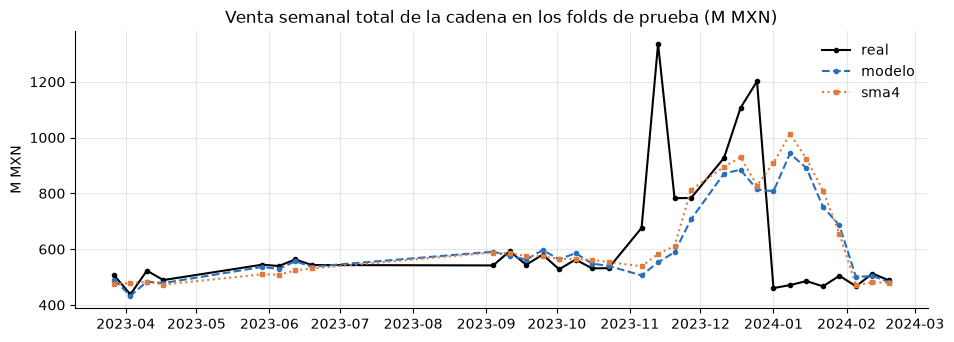

In [10]:
sem = preds.assign(semana=preds.date.dt.to_period('W-SUN').dt.start_time).groupby(['semana', 'kind']).agg(y=('y', 'sum'), pred=('pred', 'sum'), sma4=('base_sma4', 'sum')).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.6)); ax.plot(sem.semana, sem.y / 1e6, 'k-o', ms=3, label='real'); ax.plot(sem.semana, sem.pred / 1e6, color='#2a6fbb', marker='o', ms=3, ls='--', label='modelo'); ax.plot(sem.semana, sem.sma4 / 1e6, color='#e07b39', marker='s', ms=3, ls=':', label='sma4')
ax.set(title='Venta semanal total de la cadena en los folds de prueba (M MXN)', ylabel='M MXN'); ax.legend(frameon=False); plt.show()

### 4.1 Unidades derivadas del monto
Según la decisión del notebook 04: unidades = monto pronosticado ÷ precio de la serie (con datos hasta el corte de cada fold), evaluado donde `units_sold` existe.

In [11]:
rows = []
for f in [f for f in FOLDS if f.kind == 'regular']:
    cut = f.train_cutoff(14); g = preds[preds.fold == f.name].copy(); price = unit_price_by_series(p, cut)
    g['units_hat'] = derive_units(g, 'pred', price); g['units_sma4'] = derive_units(g, 'base_sma4', price)
    u = g.merge(p[['store_id', 'category', 'date', 'units_sold']], on=['store_id', 'category', 'date']).dropna(subset=['units_sold'])
    rows.append({'fold': f.name, 'WAPE unidades modelo %': wape(u.units_sold, u.units_hat) * 100, 'WAPE unidades sma4 %': wape(u.units_sold, u.units_sma4) * 100, 'sesgo modelo %': bias(u.units_sold, u.units_hat) * 100})
U = pd.DataFrame(rows).set_index('fold'); print('Nivel tienda × categoría × día (piso de ruido de las unidades ≈ 21.8 %):'); U.round(1)

Nivel tienda × categoría × día (piso de ruido de las unidades ≈ 21.8 %):


,WAPE unidades modelo %,WAPE unidades sma4 %,sesgo modelo %
fold,,,
semana_santa_2023,24.30,26.40,-2.80
may_jun_2023,23.50,25.00,-1.70
sep_2023,24.90,25.90,2.80
oct_2023,24.00,25.80,3.20
feb_2024,23.20,24.70,-1.40


**Lectura (folds regulares, media de folds).**
- **Global:** WAPE 7.5 % vs 8.2 % de `sma4`; MAPE 7.5 % vs 8.1 %; MAE ≈ 83 mil MXN por serie-semana vs 90 mil; sesgo +0.1 % vs −0.9 % (el baseline subestima sistemáticamente). Los objetivos del plan inicial (MAPE < 15 %, R² > 0.75) se cumplen con holgura (R² 0.97 en serie × semana), pero son criterios poco exigentes: el R² está dominado por la diferencia de escala entre series y el MAPE se cumplía incluso con los baselines. Por eso la decisión se tomó con WAPE contra baselines.
- **Por nivel:** en serie × día el WAPE es 16.9 % (el piso en muestra es 15.6 %, así que no hay señal de fuga: una cifra por debajo de ~15 % sería la alarma). En agregados la mejora sobre `sma4` es mayor (tienda × semana 4.3 vs 5.5; categoría o total × semana 3.2 vs 4.9), pero sigue ≈ 1 pt por encima del piso (2.1 %). En una revisión de los folds de septiembre y octubre las 6 categorías se equivocan en el mismo sentido casi todas las semanas (7 de 8), lo que indica que el error restante es sobre todo un **choque común semanal de la cadena** que los rezagos con 14 días de rezago no ven.
- **Por segmento:** la mejora es pareja (categorías −0.4 a −0.8 pts, formatos −0.5 a −0.7, regiones −0.5 a −0.7) y no hay segmento donde pierda; el sesgo es menor a 1 pt en todos. Supercenter es el formato más difícil (7.9 %).
- **Unidades (derivadas del monto, nivel tienda × categoría × día):** WAPE 23–25 % vs 25–26 % de `sma4` (mejora de 1 a 2 pts por fold); el piso de ruido de las unidades es ≈ 21.8 %, así que el margen real es pequeño. Se informa como derivado, no como un modelo propio.

## 5. Interpretabilidad (SHAP)
Valores SHAP exactos de TreeSHAP sobre el modelo final (entrenado con todos los datos), en una muestra de filas de entrenamiento.

Aditividad (SHAP + valor base = predicción en log), error máx.: 4.618527782440651e-14


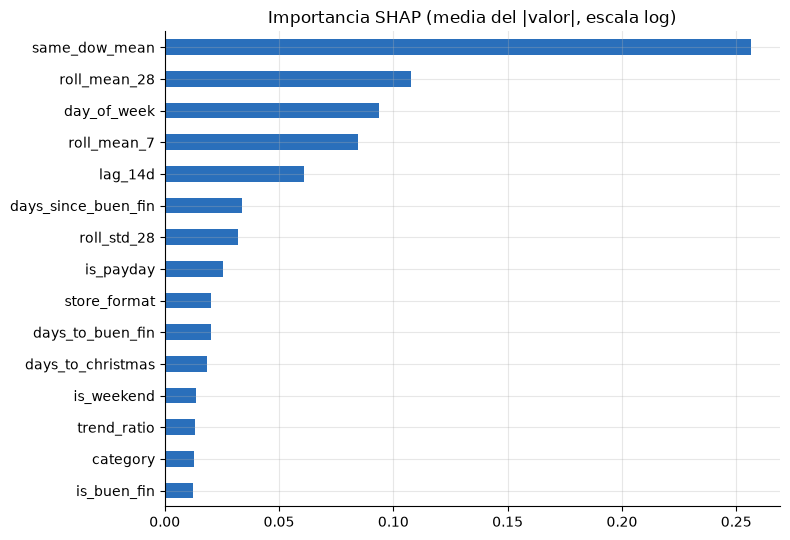

,% de la importancia total
same_dow_mean,29.20
roll_mean_28,12.20
day_of_week,10.70
roll_mean_7,9.60
lag_14d,6.90
days_since_buen_fin,3.90
roll_std_28,3.60
is_payday,2.90
store_format,2.30
days_to_buen_fin,2.30


In [12]:
import shap
model, cols_f, tr = T.train_final(F, cfg, P1, cols); X = tr[cols_f].sample(8000, random_state=0)
ex = shap.TreeExplainer(model); sv = ex.shap_values(X)
chk = model.booster_.predict(X.head(200), pred_contrib=True); print('Aditividad (SHAP + valor base = predicción en log), error máx.:', float(np.abs(sv[:200].sum(1) + ex.expected_value - model.predict(X.head(200))).max()))
imp = pd.Series(np.abs(sv).mean(0), index=cols_f).sort_values(ascending=False); imp_pct = imp / imp.sum() * 100
fig, ax = plt.subplots(figsize=(8, 5.5)); imp.head(15)[::-1].plot(kind='barh', ax=ax, color='#2a6fbb'); ax.set(title='Importancia SHAP (media del |valor|, escala log)'); plt.tight_layout(); plt.show()
imp_pct.head(12).round(1).to_frame('% de la importancia total')

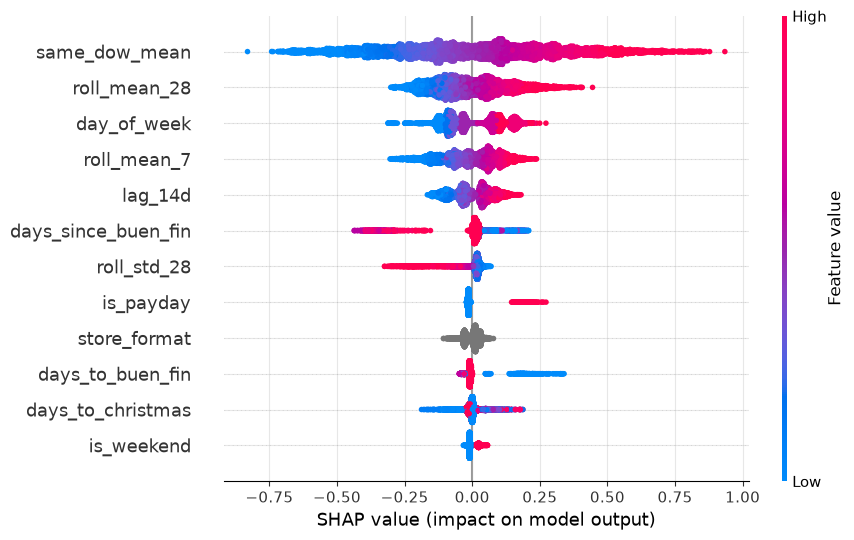

In [13]:
shap.summary_plot(sv, X, max_display=12, show=False); plt.gcf().set_size_inches(9, 5.5); plt.tight_layout(); plt.show()

**Lectura.**
- El modelo se apoya sobre todo en la **historia de la propia serie**: `same_dow_mean`, `roll_mean_28`, `roll_mean_7`, `lag_14d` y `roll_std_28` suman ≈ 62 % de la importancia; `same_dow_mean` por sí sola, 29 %. Después viene la **estacionalidad semanal** (`day_of_week` 10.7 %, `is_weekend` 1.6 %) y la **quincena** (`is_payday` 2.9 %).
- `store_format` aporta 2.3 %; `has_promotion` no aparece entre las 12 primeras, lo que coincide con la ablación.
- Las variables de distancia a Buen Fin y Navidad suman ≈ 8 %. Hay que leerlo con cautela: cada evento aparece una sola vez en el entrenamiento, así que estas variables pueden estar memorizando esa única ocurrencia y no un patrón generalizable. Su aporte real se midió en la ablación (ayudan en confirmación) pero no hay forma de validarlas fuera de muestra.
- Aditividad verificada (error ≈ 1e-14): los valores SHAP reconstruyen exactamente la predicción en escala log.

## 6. Conclusiones de la Capa 1

1. **Resultado principal:** en períodos regulares con horizonte de 14 días, LightGBM reduce el WAPE por serie-semana de 8.2 % a 7.5 % (−0.6 pts, IC95 [−1.1, −0.15]), con sesgo ≈ 0 y mejora uniforme por categoría, formato y región. Es una mejora real pero pequeña, acotada por el piso de ruido (≈ 6.5 %).
2. **La selección fue disciplinada, no oportunista:** protocolo fijado de antemano, regla de ≥ 0.2 pts, ninguna ablación ni hiperparámetro la superó; el modelo final es la configuración de referencia. Salvo la exploración previa del modelo base (disclosure al inicio), los folds de confirmación y de eventos no se usaron para elegir.
3. **Límites que hay que comunicar:** (a) en Buen Fin, Navidad y enero el modelo no supera a un baseline simple y puede errar por −35 % / +57 %; hay una sola ocurrencia de cada evento y ningún método puede aprenderlos; (b) la significancia en la confirmación por sí sola es débil (6 semanas); (c) queda un choque semanal común de la cadena sin explicar; (d) `has_promotion` se asume conocida con anticipación y no aporta al monto.
4. **Uso recomendado:** pronóstico de línea base en semanas sin eventos, con una alerta explícita (y revisión humana) en ventanas de Buen Fin, Navidad y post-Navidad.

**Siguiente:** Capa 2 (efecto de la promoción), donde el hallazgo de que la promoción no mueve el monto se contrasta con un diseño de efectos fijos.